# Task 5: Account Security
CPE342 Karena Thailand Player Intelligence. Unsupervised anomaly detection, target `is_anomaly`, metric $F_3$ (positive class: anomaly).

This notebook is the Task 5 slice of `CPE342_Master_Pipeline.ipynb`: the same cells, the same shared code in `src/` and the same cached artefacts in `outputs/`, so both produce identical predictions. It ends by writing `outputs/submission_parts/task5.csv`; `python scripts/make_submission.py` joins the five parts into `submission.csv`.

**Rules followed.** Only the provided data are used; test rows are only ever predicted (Task 5 ships only an unlabeled `test.csv`, so its unsupervised detectors are fitted on it as the brief intends); every score and decision comes from 5-fold out-of-fold validation; models are trained from scratch; no AutoML; no leaderboard probing.

## Table of Contents
1. [Imports & Configuration](#1)
2. [Data Loading & Overview](#2)
3. [Exploratory Data Analysis](#3)
4. [Data Preparation & Feature Engineering](#4)
5. [Model Training & Evaluation](#5)
6. [Hyperparameter Tuning](#6)
7. [Stacking Ensemble (K-Fold) & Final Decision](#7)
8. [Feature Importance Analysis](#8)
9. [Submission](#9)
10. [Conclusion](#10)

<a id="1"></a>
# 1. Imports & Configuration

Global seeds, warning suppression, GPU discovery, and the exact competition metric, checked on toy inputs.

In [1]:
import os, sys, json, time, warnings, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src").exists():          # notebook lives in taskN/; the shared code is one level up
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config as C
from src.config import SEED, N_FOLDS, FBETA_AVERAGE
from src.utils import seed_everything, quiet, reduce_mem_usage, timer, save_preds, load_preds, load_params
from src.metrics import (fbeta, f2, f3, macro_f1, nmae, optimize_threshold, threshold_curve,
                         optimize_class_weights, apply_class_weights)
from src.modeling import make_folds, run_cv, run_cv_sklearn
from src import viz
from src.viz import CAT, SEQ_CMAP, DIV_CMAP, MUTED, savefig

quiet()
seed_everything(SEED)
viz.set_theme()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

import torch, lightgbm, xgboost, catboost, sklearn, optuna
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | lightgbm {lightgbm.__version__} | "
      f"xgboost {xgboost.__version__} | catboost {catboost.__version__} | sklearn {sklearn.__version__} | optuna {optuna.__version__}")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
AVG_NAME = "positive-class" if FBETA_AVERAGE == "binary" else "macro"
print(f"SEED={SEED}  N_FOLDS={N_FOLDS}  FBETA_AVERAGE={FBETA_AVERAGE!r}")

# Execution switches: heavy artifacts are cached in outputs/ and re-used unless forced.
RUN_OPTUNA = False          # True -> (re)run Optuna studies in-notebook (slow); False -> load stored studies
RUN_T4_TRAINING = False     # True -> launch the Task 4 GPU K-fold fine-tuning if fold caches are missing

python 3.14.6 | torch 2.14.1+cu130 | lightgbm 4.7.0 | xgboost 3.4.1 | catboost 1.2.10 | sklearn 1.9.1 | optuna 5.0.0
device: cuda | NVIDIA GeForce RTX 4070 Laptop GPU
SEED=42  N_FOLDS=5  FBETA_AVERAGE='binary'


In [2]:
# Sanity-check the metric implementations on toy inputs
y_t = np.array([1, 1, 1, 0, 0, 0, 0, 0])
y_p = np.array([1, 1, 0, 1, 0, 0, 0, 0])
P, R = 2 / 3, 2 / 3
assert abs(fbeta(y_t, y_p, 2, "binary") - 5 * P * R / (4 * P + R)) < 1e-12
assert abs(fbeta(y_t, y_p, 3, "binary") - 10 * P * R / (9 * P + R)) < 1e-12
assert abs(nmae([0, 10, 30], [5, 10, 20]) - 1 / (1 + 15 / 40)) < 1e-12
print("metric checks passed | macro-F2 toy:", round(f2(y_t, y_p, 'macro'), 4), "| binary-F2 toy:", round(f2(y_t, y_p, 'binary'), 4))

metric checks passed | macro-F2 toy: 0.7333 | binary-F2 toy: 0.6667


<a id="2"></a>
# 2. Data Loading & Overview

Row *i* of `test.csv` maps positionally to submission id `ANS{i:05d}` (25,889 rows).

**Data card.**
* **Task 5** has 29 behaviours × 4 consecutive periods, plus static account attributes and 4 security flags. There are no labels.

In [3]:
from src import task5
t5_test = task5.load()
reduce_mem_usage(t5_test, verbose=True)
display(pd.DataFrame({"accounts (test only, no labels)": [len(t5_test)], "columns": [t5_test.shape[1] - 1],
                      "missing rate": [t5_test.isna().mean().mean()]}))

memory 25.5 MB -> 13.4 MB (47% saved)

,"accounts (test only, no labels)",columns,missing rate
0,25889,122,0.0484


<a id="3"></a>
# 3. Exploratory Data Analysis

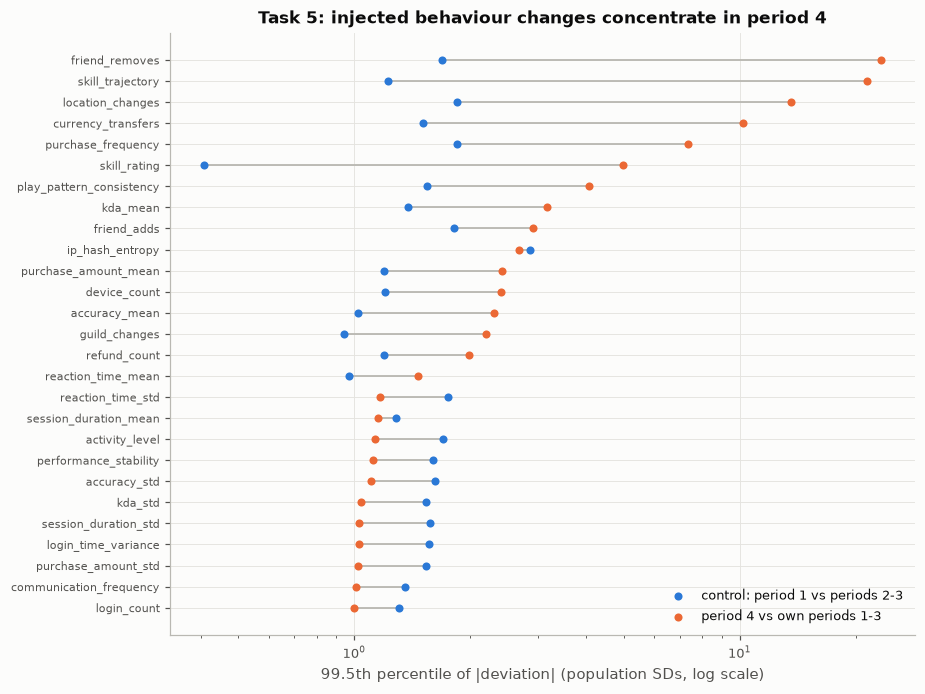

In [4]:
groups5 = [g for g in task5.temporal_groups(t5_test) if g not in ("login_lat", "login_lon")]
rows = []
for gname in groups5:
    v = t5_test[[f"{gname}_{i}" for i in range(1, 5)]].values.astype(float)
    sd = np.nanstd(v[:, :3])
    dev4 = np.abs(v[:, 3] - np.nanmean(v[:, :3], axis=1)) / sd      # period 4 vs own periods 1-3
    dev1 = np.abs(v[:, 0] - np.nanmean(v[:, 1:3], axis=1)) / sd      # control: period 1 vs periods 2-3
    rows.append([gname, np.nanpercentile(dev1, 99.5), np.nanpercentile(dev4, 99.5)])
tail = pd.DataFrame(rows, columns=["group", "control (period 1)", "period 4"]).sort_values("period 4")
fig, ax = plt.subplots(figsize=(8.5, 6.4))
ax.hlines(tail.group, tail["control (period 1)"], tail["period 4"], color=MUTED, lw=1.2)
ax.scatter(tail["control (period 1)"], tail.group, color=CAT[0], s=28, label="control: period 1 vs periods 2-3", zorder=3)
ax.scatter(tail["period 4"], tail.group, color=CAT[1], s=28, label="period 4 vs own periods 1-3", zorder=3)
ax.set_xscale("log"); ax.set_xlabel("99.5th percentile of |deviation| (population SDs, log scale)")
ax.set_title("Task 5: injected behaviour changes concentrate in period 4"); ax.legend(loc="lower right")
ax.tick_params(axis="y", labelsize=7.5)
plt.tight_layout(); savefig(fig, "t5_eda_tails"); plt.show()

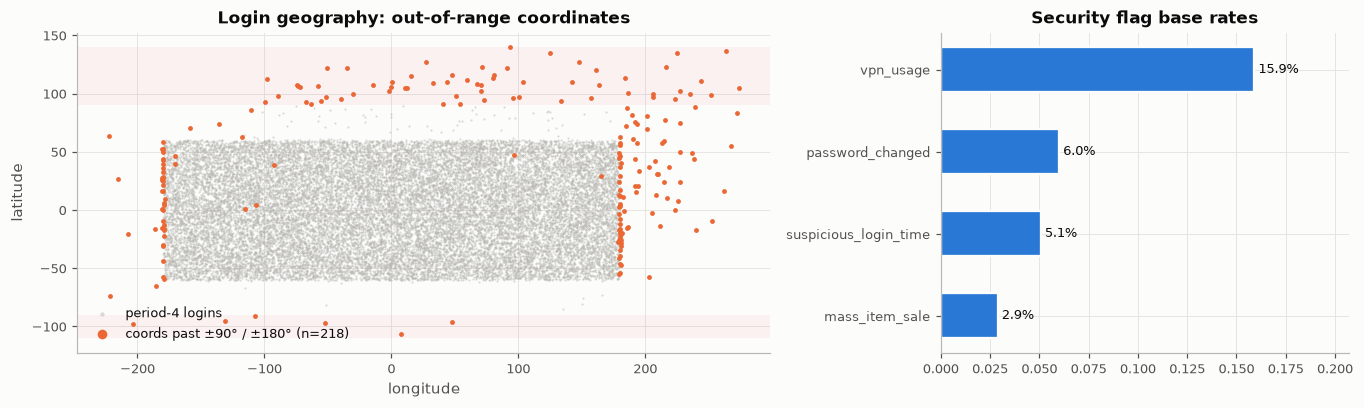

In [5]:
lat = t5_test[[f"login_lat_{i}" for i in range(1, 5)]]
lon = t5_test[[f"login_lon_{i}" for i in range(1, 5)]]
invalid = (lat.abs() > 90).any(axis=1) | (lon.abs() > 180).any(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={"width_ratios": [1.7, 1]})
axes[0].scatter(t5_test.login_lon_4, t5_test.login_lat_4, s=2, color=MUTED, alpha=0.5, label="period-4 logins")
axes[0].scatter(t5_test.login_lon_4[invalid], t5_test.login_lat_4[invalid], s=10, color=CAT[1], label=f"coords past ±90° / ±180° (n={invalid.sum()})")
axes[0].axhspan(90, 140, color=CAT[7], alpha=0.06); axes[0].axhspan(-110, -90, color=CAT[7], alpha=0.06)
axes[0].set_xlabel("longitude"); axes[0].set_ylabel("latitude"); axes[0].legend(loc="lower left", markerscale=2)
axes[0].set_title("Login geography: out-of-range coordinates")
flags = task5.FLAG_COLS
fr = t5_test[flags].mean().sort_values()
axes[1].barh(fr.index, fr.values, color=CAT[0], height=0.55, **viz.bar_gap())
for i, v in enumerate(fr.values):
    axes[1].text(v, i, f" {v:.1%}", va="center", fontsize=8.5)
axes[1].set_xlim(0, fr.max() * 1.3); axes[1].set_title("Security flag base rates")
plt.tight_layout(); savefig(fig, "t5_eda_geo"); plt.show()

**Findings.** For every behaviour, the deviation of **period 4 from the account's own periods 1–3** behaves like the control (period 1 vs 2–3) up to the ~98th percentile. Then it explodes for specific families:
* **Takeover / boosting:** `skill_rating`, `skill_trajectory`, `kda_mean`, `accuracy_mean` jump, `friend_removes` spikes and reaction time drops. These co-occur.
* **Credential theft / VPN abuse:** `location_changes`, `currency_transfers` and `purchase_*` spikes with long login jumps, plus a drop in `play_pattern_consistency`.
* **Out-of-range coordinates are not a rule on their own.** About two thirds belong to those teleporting accounts. The rest are players near the date line whose longitude wraps past ±180° with no actual travel. The geo signal is therefore the wrap-aware great-circle jump (haversine), not the coordinate range.

So one anomaly signature is a **change relative to the account's own baseline**, which drives the feature engineering below. §5.3 shows a second kind that never changes: accounts that are abnormal in *every* period (single-IP clockwork bots, near-zero activity or chat, very low `behavior_stability`).

## 3.6 Data-quality audit (all tasks)
Before any modelling, `src/audit.py` checks every task on features only (no test label exists, and nothing here is fitted for a model):
* **Distribution shift.** Adversarial validation: a LightGBM tries to tell train rows from test rows. Three views locate a shift: all features, only the missing-value indicators, and the values with missing cells filled by the train median. A per-column Kolmogorov–Smirnov statistic on the observed values completes it.
* **Missing values: informative or random?** For every column, a chi-square (classes) or Mann–Whitney (spending) test of the target against "cell is missing". If no column is informative, the cells are missing completely at random, and imputing them or adding indicators cannot add signal.
* **Impossible values.** Percentages outside [0, 100], coordinates off the globe, negative counts, sentinel codes, and spikes at a column's minimum or maximum.
* **Duplicate rows, constant columns and collinear pairs** (|Spearman| > 0.98), plus a scan of all Task 4 images.

### Data-quality audit
Adversarial validation (train vs test), missing values vs target, impossible values, duplicates and collinearity, computed by `src/audit.py` on features only (see the master notebook §3.6).

In [6]:
from src import audit
with pd.option_context("display.max_colwidth", 200):
    display(pd.Series(audit.task_audit(None, t5_test), name="Task 5").to_frame())

,Task 5
physical issues,"login_lon_1: 30 longitudes outside [-180, 180]; login_lon_2: 36 longitudes outside [-180, 180]; login_lon_3: 41 longitudes outside [-180, 180]; login_lat_4: 71 latitudes outside [-90, 90]; login_l..."
duplicate test rows,0
constant columns,0
collinear pairs (|Spearman| > 0.98),"login_lat_1 ~ login_lat_2, login_lat_1 ~ login_lat_3, login_lat_1 ~ login_lat_4, login_lon_1 ~ login_lon_2, login_lon_1 ~ login_lon_3, login_lon_1 ~ login_lon_4, login_lat_2 ~ login_lat_3, login_l..."


**Audit findings.**
* **Missing values in Tasks 1–3:** no column is informative at p < 0.001. The cells are missing completely at random.
* **Impossible values:** none need cleaning. No percentage leaves [0, 100]. Several bounded scores are clipped at their limits (e.g. 8% of `aiming_smoothness` = 1 in Task 1), which trees handle. `account_age_days = 999` in Tasks 2/3 is not a sentinel: neighbouring values are just as frequent.
* **Task 5:** 207 accounts log in from coordinates past ±90° / ±180°. About two thirds are teleporting accounts; the rest are date-line wraps, handled by the wrap-aware haversine features (§3.5). `refund_count_2/3 = −1` in 16% of accounts is a floor value with the same anomaly rate as everyone else.
* **Duplicates / collinearity:** no duplicate rows within or across splits and no constant columns. The only collinear pairs are known structure: historical vs previous-month spending (Task 3, ratio 0.30–0.40) and the per-period location and skill-rating series (Task 5).

<a id="4"></a>
# 4. Data Preparation & Feature Engineering

## 4.5 Task 5: impossible travel, self-referential deviations and burstiness
* **Geodesic features:** Haversine distance between consecutive login coordinates (1→2→3→4), max hop, total path, period-4 distance from the account's historical centroid, km per login in period 4, and an **invalid-coordinate flag** ($|lat|>90°$ or $|lon|>180°$).
* **Self-referential deviation (for each of the 27 behaviours):** `dev4` = (x₄ − mean(x₁..x₃)) / population SD, `selfz4`, the same scaled by the account's own variability, `maxjump`, the largest first difference, `burst`, max / mean, and `cv`, the dispersion over the 4 periods.
* Static attributes and the 4 security flags (plus their count).

In [7]:
X5, dev5 = task5.build_features(t5_test)
geo5 = [c for c in X5.columns if c.startswith("geo_")]
selfz5 = [c for c in X5.columns if c.endswith("_selfz4")]
dyn5 = [c for c in X5.columns if c.endswith(("_maxjump", "_burst", "_cv"))]
static5 = task5.STATIC_COLS + ["n_flags"]
print(f"Task 5 engineered matrix: {X5.shape} | dev4: {len(dev5)} | selfz4: {len(selfz5)} | dynamics: {len(dyn5)} | geo: {len(geo5)}")
display(X5[["geo_hop_34", "geo_p4_from_home_km", "geo_invalid_coord", "skill_rating_dev4", "friend_removes_dev4",
            "currency_transfers_dev4", "location_changes_dev4"]].describe(percentiles=[.5, .99, .999]).T.round(3))

Task 5 engineered matrix: (25889, 179) | dev4: 27 | selfz4: 27 | dynamics: 81 | geo: 9


,count,mean,std,min,50%,99%,99.9%,max
geo_hop_34,"21,193.0000",215.3870,970.5230,0.9050,85.1670,"6,233.2460","11,147.6140","13,233.7400"
geo_p4_from_home_km,"23,390.0000",195.1010,924.2670,0.2420,69.9260,"5,789.5380","10,842.0790","12,305.0700"
geo_invalid_coord,"25,889.0000",0.0080,0.0910,0.0000,0.0000,0.0000,1.0000,1.0000
skill_rating_dev4,"24,608.0000",0.0570,0.5980,-0.5560,0.0010,2.5660,8.4930,10.7520
friend_removes_dev4,"24,651.0000",0.2550,2.4350,-1.3980,0.0000,14.4990,29.8230,32.4320
currency_transfers_dev4,"24,668.0000",0.1110,1.1250,-1.4420,-0.0000,6.5510,13.5090,15.6460
location_changes_dev4,"24,639.0000",0.2140,1.6290,-1.5960,0.0020,10.6480,17.7430,20.3760


<a id="5"></a>
# 5. Model Training & Evaluation

Task 5 has no labels, so there is no train/validation split. The detectors are fitted on the unlabeled accounts, and their agreement with the gap-separated families is the diagnostic.

In [8]:
from sklearn.metrics import roc_auc_score, confusion_matrix, f1_score
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer


def cached(name, fn, force=False):
    # Return {'oof','test',...} arrays, training via fn() only when no cache exists.
    r = load_preds(name)
    if r is None or force:
        t0 = time.time()
        out = fn()
        r = {k: np.asarray(v) for k, v in out.items() if k in ("oof", "test", "p_oof", "mu_oof", "p_test", "mu_test", "sigma", "smear", "n_iter")}
        save_preds(name, **r)
        print(f"  trained {name} in {time.time() - t0:.0f}s")
    return r

BASE = {"learning_rate": 0.05}
summary = []   # running scoreboard

### 5.3 Task 5: anomaly families and detector diagnostics (no labels)
Before scoring detectors, we ask how the anomalies are *distributed*. EDA showed that `behavior_stability` is uniform on 0.70–0.95 for 99% of accounts, while 274 accounts sit on 0.20–0.40 with **nothing in between**. A long tail does not leave an empty gap. A separate population of planted or anomalous behaviour does.

`task5.gap_clusters` turns this into a label-free detector that runs on every column. In each 10% tail it tests the widest empty gaps. With $d$ the density of the 200 accounts next to the gap and $w$ its width, $\lambda = d\,w$ is the number of accounts we would *expect* inside the gap if the bulk simply continued, and $P(\text{gap empty}) \approx e^{-\lambda}$. Accounts beyond a gap with $\lambda \ge 50$ form an **isolated tail cluster**. Groups under 20 accounts are individual outliers, not populations; this excludes, for example, longitudes that wrap past ±180° for players near the date line. Groups over 3% are zero-inflated counts. Clusters that share accounts are merged into **families** (union-find, overlap ≥ 50%). One family is one behaviour seen through several columns: a bot shows low IP entropy *and* clockwork login times *and* constant session lengths.

The result does not hinge on these settings. The flagged set is the identical 1,811 accounts for $\lambda \ge$ 50, 100 or 300, neighbourhoods of 100–400 accounts, tails of 5–15%, and minimum group sizes of 10–50. Only a much looser $\lambda \ge 20$ adds 40 borderline accounts.

The families then serve as a yardstick for the six statistical detectors: which behaviours does each one see in its top 7%?

group,size,share,gap_from,gap_to,expected_in_gap
friend_removes_4 > 12.45,297,1.15%,4.800,20.107,"42,064"
behavior_stability < 0.5499,246,0.95%,0.400,0.700,"29,912"
ip_hash_entropy_4 < 0.2496,194,0.75%,0.199,0.300,"5,431"
ip_hash_entropy_1 < 0.2492,198,0.76%,0.198,0.300,"5,016"
ip_hash_entropy_3 < 0.2494,197,0.76%,0.199,0.300,"4,862"
ip_hash_entropy_2 < 0.2498,199,0.77%,0.200,0.300,"4,227"
purchase_frequency_4 > 8.022,189,0.73%,5.997,10.047,"2,073"
currency_transfers_4 > 15.99,293,1.13%,11.961,20.012,"1,982"
location_changes_4 > 4.317,493,1.90%,3.587,5.047,"1,138"
login_time_variance_4 < 1.102,195,0.75%,0.500,1.705,"1,067"


family,accounts,share,columns that isolate it
takeover / VPN abuse,517,2.00%,7
skill boost + friend purge,310,1.20%,2
near-inactive,265,1.02%,4
silent (no chat),263,1.02%,4
erratic (low stability),247,0.95%,2
single-IP bots,207,0.80%,14


33 isolated tail clusters -> 6 families -> 1,809 accounts (6.99%)
  ExtremeValue        0.1s


  IsolationForest     3.4s


  ECOD                2.0s


  COPOD               0.8s


  LOF                 1.3s


  Mahalanobis(MCD)   11.7s


  AutoEncoder        23.4s


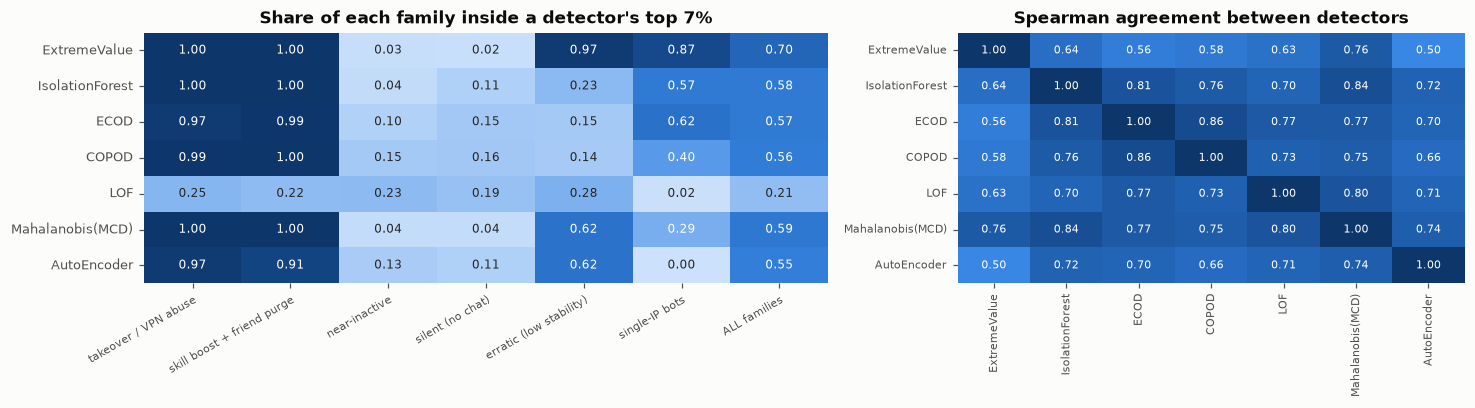

In [9]:
cols5 = task5.detector_columns(X5)
Z5 = task5.detector_matrix(X5, cols5, "robust")
gc_table, gc_masks = task5.gap_clusters(t5_test, X5)
gc_fams = task5.merge_families(gc_masks)
FAMILY_NAMES = {"friend_removes_4": "skill boost + friend purge", "behavior_stability": "erratic (low stability)",
                "location_changes_4": "takeover / VPN abuse", "activity_level": "near-inactive",
                "communication_frequency": "silent (no chat)", "ip_hash_entropy": "single-IP bots"}
def fam_name(groups):
    for g in groups:
        for key, nm in FAMILY_NAMES.items():
            if g.startswith(key):
                return nm
    return groups[0]
fam_mask = {fam_name(f): gc_masks[f].any(axis=1).values for f in sorted(gc_fams, key=lambda f: -gc_masks[f].any(axis=1).sum())}
gap5 = gc_masks.any(axis=1).values
display(gc_table[["group", "size", "share", "gap_from", "gap_to", "expected_in_gap"]].style.format(
    {"share": "{:.2%}", "gap_from": "{:.3f}", "gap_to": "{:.3f}", "expected_in_gap": "{:,.0f}"}).hide(axis="index"))
display(pd.DataFrame([[nm, int(m.sum()), m.mean(), len(f)] for (nm, m), f in zip(fam_mask.items(), sorted(gc_fams, key=lambda f: -gc_masks[f].any(axis=1).sum()))],
                     columns=["family", "accounts", "share", "columns that isolate it"]).style.format({"share": "{:.2%}"}).hide(axis="index"))
print(f"{len(gc_table)} isolated tail clusters -> {len(gc_fams)} families -> {gap5.sum():,} accounts ({gap5.mean():.2%})")

det_scores = {}
for name, fn in task5.DETECTORS.items():
    t0 = time.time()
    s = fn(Z5, device=DEVICE) if name == "AutoEncoder" else fn(Z5)
    det_scores[name] = task5.robust_z(s)
    print(f"  {name:17s} {time.time() - t0:5.1f}s")

BUDGET = 0.07
cov = pd.DataFrame({name: {**{k: (s >= np.quantile(s, 1 - BUDGET))[m].mean() for k, m in fam_mask.items()},
                           "ALL families": (s >= np.quantile(s, 1 - BUDGET))[gap5].mean()}
                    for name, s in det_scores.items()}).T
fig, axes = plt.subplots(1, 2, figsize=(13.5, 3.8), gridspec_kw={"width_ratios": [1.35, 1]})
sns.heatmap(cov, annot=True, fmt=".2f", cmap=SEQ_CMAP, vmin=0, vmax=1, ax=axes[0], cbar=False, annot_kws={"size": 8})
axes[0].set_title(f"Share of each family inside a detector's top {BUDGET:.0%}"); axes[0].tick_params(axis="x", rotation=30, labelsize=7.5)
plt.setp(axes[0].get_xticklabels(), ha="right", rotation_mode="anchor")
corr5 = pd.DataFrame(det_scores).corr("spearman")
sns.heatmap(corr5, annot=True, fmt=".2f", cmap=SEQ_CMAP, vmin=0, vmax=1, ax=axes[1], cbar=False, annot_kws={"size": 7.5})
axes[1].set_title("Spearman agreement between detectors"); axes[1].tick_params(labelsize=7.5)
plt.tight_layout(); savefig(fig, "t5_detectors"); plt.show()

**Reading the diagnostics.** Six families account for 7.0% of accounts. Each is cut off from normal behaviour by a gap that should hold hundreds to tens of thousands of accounts if it were just a tail.

* **Every detector except LOF sees the spike families.** Teleports, transfers and purchase spikes (takeover / VPN abuse), and skill jumps with friend purges, land in the top 7% for 96–100% of their accounts.
* **Coverage of the "too low" families depends on the gap's distance from the bulk.** Very low `behavior_stability` and single-IP bots sit 5–6 robust SDs (1.4826·MAD) below the median. The extreme-value detector, autoencoder and MCD catch the low-stability family (0.97 / 1.00 / 0.80). Bots are caught mostly by the extreme-value detector (0.81).
* **Near-inactive and silent accounts are invisible to all of them (≤ 0.22).** Their activity and chat levels sit only about 2 robust SDs below the median. In 70 dimensions they are swamped by accounts that are merely noisy, the classic weakness of distance and density scores on bounded features. Yet their gaps are unmistakable: zero accounts where hundreds are expected.
* **LOF covers little of anything (≤ 0.29).** Local density ratios in 70 dimensions mostly react to noise.

The gap-cluster detector therefore finds what the statistical detectors miss. §7.5 checks whether the score ensemble and the hard-evidence rules find anything *beyond* the families, since under $F_3$ a missed anomaly costs far more than a false alarm.

<a id="6"></a>
# 6. Hyperparameter Tuning

Task 5 has no labels, so there is no objective to tune against. Instead, §5 shows that the gap detector's output does not depend on its settings: the identical 1,811 accounts are flagged for λ ≥ 50, 100 or 300, neighbourhoods of 100–400 accounts, tails of 5–15% and minimum group sizes of 10–50.

<a id="7"></a>
# 7. Stacking Ensemble (K-Fold) & Final Decision

The unsupervised evidence (gap families, score ensemble, hard-evidence rules) is weighed for the $F_3$ metric: the gap families are flagged, and the other two serve as cross-checks.

## 7.5 Task 5: Final decision (six families + one dependence pocket; score ensemble and rules as cross-checks)
1. **Score ensemble.** Each retained detector's raw score is robust-z standardised (median/MAD) and the results are averaged (LOF excluded, §5.3). The knee (Kneedle) of the sorted log-excess marks where scores stop falling steeply.
2. **Isolated tail clusters (§5.3).** Every account in a gap-separated family is flagged. Their membership needs no threshold choice: the gap *is* the threshold, and it is set by the data.
3. **F3 asymmetry.** For a perfect ranker with true rate $r$ that flags a fraction $q$, $F_3(q) = \frac{10\,\min(q,r)/q}{9\,\min(q,r)/q + \min(q,r)/r}$. Missing anomalies is about 9× costlier than a false alarm, so a whole family the score ensemble cannot see (near-inactive, silent accounts) has to be caught by the family detector.
4. **Ensemble alerts outside the families.** They are inspected below. Their largest robust z is modest, and they are enriched for the four yes/no flags only because the ensemble reads those flags as inputs. Outside the families the flags are statistically independent: the number of accounts with 0, 1, 2 or 3 flags matches the independence prediction almost exactly. So *statistically* they look like the noisy edge of normal behaviour.
5. **Are the families complete?** The gap detector of §5.3 scans the raw columns. A planted behaviour could hide from it if it only shows up as a *change* against the account's own history. So we rerun the same detector on the derived per-account features: period-4 shift, jumps, burstiness, all-period levels and geo hops. Every isolated group it finds there lies inside the six families. Two independent views of the data agree that there is no further *gap-separated* population. Point 7 looks for a group that has no gap at all.
6. **Union or families?** Task 5 has no labels, so we cannot see the organisers' anomaly definition. $F_3$ weighs recall 9× more than precision: the Bayes-optimal $F_\beta$ decision flags every account whose anomaly probability exceeds $F^*/(1+\beta^2) \approx F^*/10$ (Lipton et al., 2014). That argues for adding the ensemble and rule alerts *if* they have a real chance of being anomalies. The table below scores each candidate rule as if each of the others were the truth. The evidence says the extra alerts do not clear that bar: they look like the noisy edge of normal behaviour (point 4), and nothing outside the families forms a population (point 5). We therefore do not add them. A submission using the union (v4: public LB 0.69429 against 0.69663 for the families) agrees with this.
7. **A group without a gap: dependence pockets.** A behaviour can be unusual in two features *at once* without being extreme in either, so it leaves no 1-D gap. Normal accounts draw their features almost independently: on a 20×20 quantile grid of a feature pair, every cell should then hold $n/400$ accounts. We scan all ~11,300 feature pairs outside the families (pairs built from the same behaviour, or from a built-in ratio such as km per login, are skipped) and record each pair's most over-full cell, $z = (\text{observed} - \text{expected})/\sqrt{\text{expected}}$. The noise level is the largest $z$ of the same scan on column-shuffled data, which keeps every marginal and destroys every group. Exactly **one** pocket clears it by far: very high match-to-match spread of KDA *and* of accuracy (erratic performance, e.g. a shared or boosted account). After flagging it, no pocket is left above the noise level.
8. **A label-free cut-off for the pocket.** Score = the lower of the two rank percentiles (high only if both are high). Shuffling the columns again gives, for every cut-off $k$, the expected number of normal accounts among the top $k$; so $k$ minus that number estimates the true members, without labels. We choose $k$ to maximise the expected $F_3$, counting the families as true. Each flagged account then has a much higher chance of being anomalous than the $F^*/10$ bar of point 6. The final flags are the **six families plus the pocket**.

,ExtremeValue,IsolationForest,ECOD,COPOD,LOF,Mahalanobis(MCD),AutoEncoder
LOO-consensus Spearman,0.6957,0.8602,0.8417,0.8155,0.8288,0.9126,0.7501
in fusion,True,True,True,True,False,True,True


score-ensemble knee: top 7.84% | families: 6.99% | ensemble ROC-AUC for family membership: 0.9030


,accounts,caught by ensemble knee
takeover / VPN abuse,517,100.0%
skill boost + friend purge,310,100.0%
near-inactive,265,8.3%
silent (no chat),263,8.4%
erratic (low stability),247,62.3%
single-IP bots,207,51.7%


ensemble-only alerts: 899 | median of their largest |robust z|: 1.49 (families 2.90, unflagged accounts 1.01)
binary-flag rates (password / vpn / odd-hour / mass-sale): {'ensemble-only': [0.16200000047683716, 0.22599999606609344, 0.1679999977350235, 0.546999990940094], 'unflagged': [0.04399999976158142, 0.15000000596046448, 0.04600000008940697, 0.0]}


flags set,0,1,2,3,4
accounts observed,"14,711.0000","4,534.0000",378.0000,15.0000,0.0000
expected if independent,"14,734.6000","4,485.9000",403.4000,13.9000,0.2000


derived-feature gap scan: 39 isolated groups covering 1,562 accounts; outside the six families: 0


,accounts flagged,truth = gap families,truth = ensemble knee + evidence rules,truth = families ∩ (knee + rules),worst case
gap families,1809,1.000,0.590,0.965,0.590
ensemble knee + evidence rules,2290,0.712,1.000,0.932,0.712
union of all three,2776,0.949,0.979,0.901,0.901


dependence-pocket scan outside the families: 11,319 feature pairs; noise level (max z on shuffled data) 10.9; pockets above it: 1


,z,a,b,bin_a,bin_b,observed,expected
0,21.0000,accuracy_std_level,kda_std_level,19,19,223.0000,60.3000
1,8.7000,friend_removes_level,guild_changes_burst,1,17,128.0000,60.2000
2,8.7000,friend_removes_burst,guild_changes_burst,1,17,128.0000,60.2000
3,8.6000,friend_removes_cv,guild_changes_burst,1,17,127.0000,60.2000
4,8.5000,friend_removes_maxjump,guild_changes_burst,1,17,126.0000,60.1000


pocket detector on ['accuracy_std_level', 'kda_std_level']: estimated group size 201; cut-off k = 339 (estimated members 194, precision 0.57); expected F3 families only 0.909 -> with the pocket 0.990


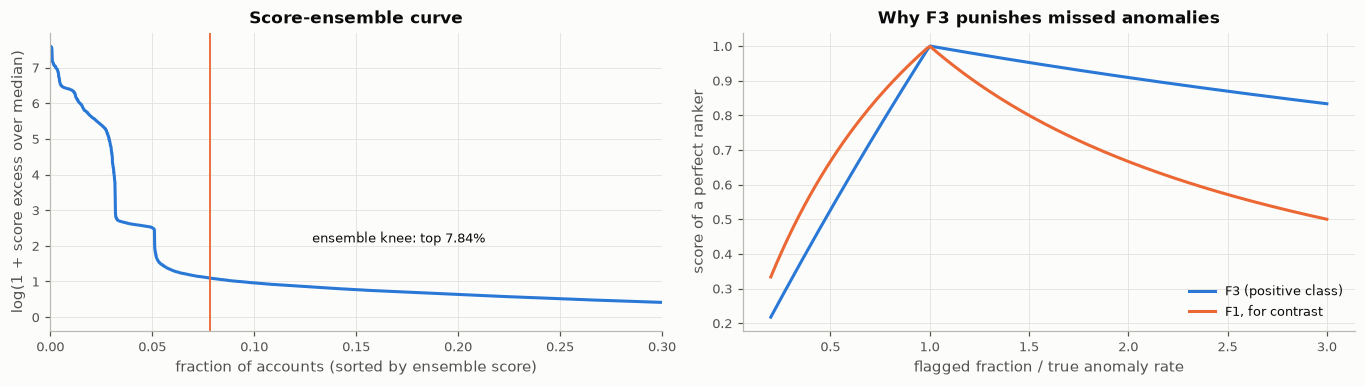

FINAL Task 5 flags: 2,148 = 8.30% of accounts (six gap-separated families 1,809 + dependence pocket 339)


In [10]:
members = [k for k in det_scores if k != "LOF"]
M5 = np.column_stack([det_scores[k] for k in members])
w_sel, agree = task5.consensus_weights(np.column_stack(list(det_scores.values())))
display(pd.DataFrame({"LOO-consensus Spearman": agree, "in fusion": [k in members for k in det_scores]}, index=list(det_scores)).T)
consensus = M5.mean(axis=1)
s_sorted = np.sort(consensus)[::-1]
log_excess = np.log1p(np.clip(s_sorted - np.median(s_sorted), 0, None))
knee = task5.knee_point(log_excess)
Q5 = knee / len(consensus)
flag_ml = consensus >= s_sorted[knee]
print(f"score-ensemble knee: top {Q5:.2%} | families: {gap5.mean():.2%} | ensemble ROC-AUC for family membership: {roc_auc_score(gap5, consensus):.4f}")
rec = pd.DataFrame({"accounts": {k: int(m.sum()) for k, m in fam_mask.items()},
                    "caught by ensemble knee": {k: flag_ml[m].mean() for k, m in fam_mask.items()}})
display(rec.style.format({"caught by ensemble knee": "{:.1%}"}))

# ensemble-only alerts: do they look like a population, or like the noisy edge of normal behaviour?
extra = flag_ml & ~gap5
normal = ~flag_ml & ~gap5
zdf = pd.DataFrame(Z5, columns=cols5)
top_abs = zdf.abs().max(axis=1)
print(f"ensemble-only alerts: {extra.sum():,} | median of their largest |robust z|: {np.median(top_abs[extra]):.2f} "
      f"(families {np.median(top_abs[gap5]):.2f}, unflagged accounts {np.median(top_abs[normal]):.2f})")
print("binary-flag rates (password / vpn / odd-hour / mass-sale):",
      {nm: np.round(t5_test.loc[m, task5.FLAG_COLS].mean().values, 3).tolist() for nm, m in [("ensemble-only", extra), ("unflagged", normal)]})
# The ensemble reads the four flags as inputs, so ensemble-only alerts are enriched for flags by construction.
# Is "several flags at once" a population of its own? Outside the families, compare the number of flags
# per account with what independent flags would produce (Poisson-binomial).
Fl = t5_test.loc[~gap5, task5.FLAG_COLS].dropna()
pr = Fl.mean().values
expd = np.array([1.0])
for r in pr:
    expd = np.convolve(expd, [1 - r, r])
nflag = Fl.sum(axis=1).astype(int).value_counts().reindex(range(5), fill_value=0)
display(pd.DataFrame({"accounts observed": nflag.values, "expected if independent": np.round(expd * len(Fl), 1)},
                     index=pd.Index(range(5), name="flags set")).T)

# Completeness check: the same gap detector on the derived per-account features (period-4 change, jumps, levels, geo)
Xd5 = X5.drop(columns=[c for c in X5.columns if c in task5.STATIC_COLS or c in ("n_flags", "n_missing")])
gd_table, gd_masks = task5.gap_clusters(Xd5)
gd_any = gd_masks.any(axis=1).values
print(f"derived-feature gap scan: {len(gd_table)} isolated groups covering {gd_any.sum():,} accounts; "
      f"outside the six families: {int((gd_any & ~gap5).sum())}")

# Candidate rules, each scored as if each candidate were the ground truth
rules5 = task5.evidence_rules(t5_test)
rule5 = rules5.any(axis=1).values
cands5 = {"gap families": gap5, "ensemble knee + evidence rules": flag_ml | rule5, "union of all three": gap5 | flag_ml | rule5}
truths5 = {"gap families": gap5, "ensemble knee + evidence rules": flag_ml | rule5, "families ∩ (knee + rules)": gap5 & (flag_ml | rule5)}
rob5 = pd.DataFrame({f"truth = {tn}": {dn: f3(t.astype(int), d.astype(int)) for dn, d in cands5.items()} for tn, t in truths5.items()})
rob5["worst case"] = rob5.min(axis=1)
rob5.insert(0, "accounts flagged", [int(d.sum()) for d in cands5.values()])
display(rob5.style.format({c: "{:.3f}" for c in rob5.columns if c != "accounts flagged"}))
# point 7: blind dependence-pocket scan outside the families; point 8: label-free detector and cut-off
scan5, noise5 = task5.dependence_pockets(X5, ~gap5)
sig5 = scan5[scan5.z > noise5]
print(f"dependence-pocket scan outside the families: {len(scan5):,} feature pairs; noise level (max z on shuffled data) "
      f"{noise5:.1f}; pockets above it: {len(sig5)}")
display(scan5.head(5).round(1))
pocket_feats5 = sorted(set(sig5.a) | set(sig5.b))
pocket5, pinfo5 = task5.pocket_detector(X5, gap5, pocket_feats5)
print(f"pocket detector on {pocket_feats5}: estimated group size {pinfo5['group_size']:.0f}; cut-off k = {pinfo5['k']} "
      f"(estimated members {pinfo5['est_tp']:.0f}, precision {pinfo5['precision']:.2f}); expected F3 families only "
      f"{pinfo5['expected_f_known_only']:.3f} -> with the pocket {pinfo5['expected_f']:.3f}")
flag5 = gap5 | pocket5
pred5 = flag5.astype(int)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
ranks = np.arange(1, len(s_sorted) + 1) / len(s_sorted)
axes[0].plot(ranks, log_excess, color=CAT[0], label="all accounts")
axes[0].axvline(Q5, color=CAT[1], lw=1.2)
axes[0].annotate(f"ensemble knee: top {Q5:.2%}", (Q5, log_excess[knee]), xytext=(Q5 + 0.05, log_excess[knee] + 1.0), fontsize=8.5,
                 arrowprops=dict(arrowstyle="-", color=MUTED))
axes[0].set_xlim(0, 0.3); axes[0].set_xlabel("fraction of accounts (sorted by ensemble score)")
axes[0].set_ylabel("log(1 + score excess over median)"); axes[0].set_title("Score-ensemble curve")
r_true = gap5.mean()
qs = np.linspace(0.2, 3, 200) * r_true
axes[1].plot(qs / r_true, task5.expected_fbeta(qs, r_true, 3), color=CAT[0], label="F3 (positive class)")
axes[1].plot(qs / r_true, task5.expected_fbeta(qs, r_true, 1), color=CAT[1], label="F1, for contrast")
axes[1].set_xlabel("flagged fraction / true anomaly rate"); axes[1].set_ylabel("score of a perfect ranker")
axes[1].set_title("Why F3 punishes missed anomalies"); axes[1].legend(loc="lower right")
plt.tight_layout(); savefig(fig, "t5_threshold"); plt.show()
print(f"FINAL Task 5 flags: {pred5.sum():,} = {pred5.mean():.2%} of accounts (six gap-separated families {gap5.sum():,} + dependence pocket {pocket5.sum():,})")
AGREE5 = roc_auc_score(gap5, consensus)
summary.append(["Task 5", "ensemble ROC-AUC vs families (agreement)", AGREE5,
                "6 gap-separated families (1-D density-gap detector) + 1 dependence pocket (2-D scan, permutation-null cut-off) + 6-detector ensemble cross-check"])

<a id="8"></a>
# 8. Feature Importance Analysis

Every alert is explained by the behaviour that isolates it (the family's gap column).

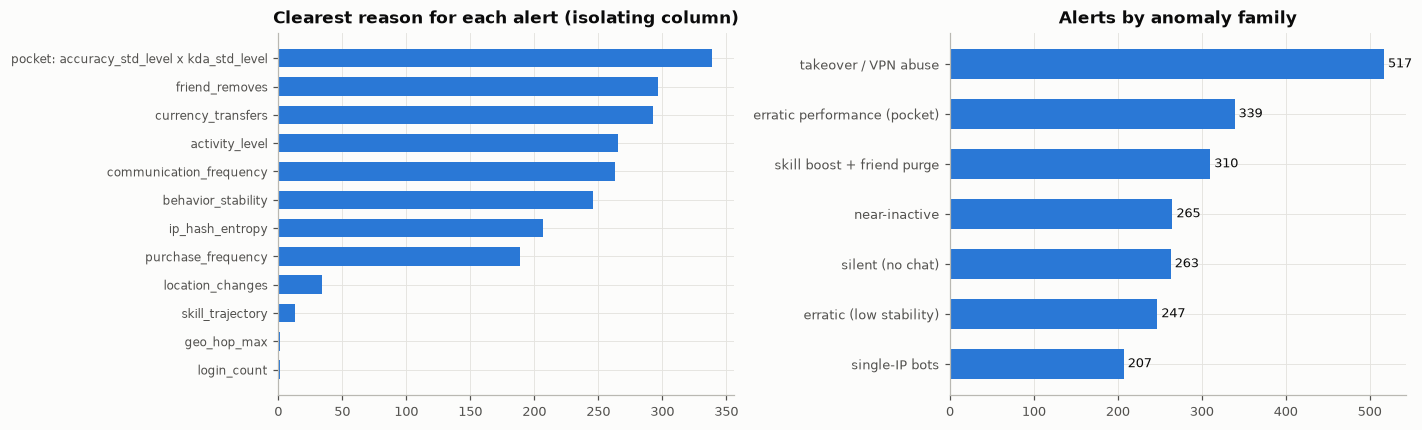

In [11]:
flagged = np.where(pred5 == 1)[0]
# reason = the column that isolates the account most clearly (largest expected-in-gap among its clusters)
order = gc_table.group.tolist()
G = gc_masks[order].values[flagged]
R5 = rules5.values[flagged]
reason = pd.Series([gc_table.column[int(np.argmax(g))] if g.any() else
                    ("pocket: " + " x ".join(pocket_feats5) if pocket5[i] else
                     f"rule: {rules5.columns[int(np.argmax(r))]}" if r.any() else "score ensemble (multivariate)")
                    for i, g, r in zip(flagged, G, R5)]).str.replace(r"_[1-4]$", "", regex=True)
drv = reason.value_counts().head(14).sort_values()
fam_counts = pd.Series({k: int((m & (pred5 == 1)).sum()) for k, m in fam_mask.items()})
if pocket5.any():
    fam_counts["erratic performance (pocket)"] = int(pocket5.sum())
if (flag5 & ~gap5 & ~pocket5).any():
    fam_counts["no family (ensemble / rules)"] = int((flag5 & ~gap5 & ~pocket5).sum())
fam_counts = fam_counts.sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh(drv.index, drv.values, color=CAT[0], height=0.65); axes[0].set_title("Clearest reason for each alert (isolating column)")
axes[0].tick_params(axis="y", labelsize=8)
axes[1].barh(fam_counts.index, fam_counts.values, color=CAT[0], height=0.6)
for i, v in enumerate(fam_counts.values):
    axes[1].text(v, i, f" {v}", va="center", fontsize=8.5)
axes[1].set_title("Alerts by anomaly family"); axes[1].tick_params(axis="y", labelsize=8.5)
plt.tight_layout(); savefig(fig, "t5_drivers"); plt.show()

**Business reading (security).** Every alert comes with a family and the behaviour that isolates it, so the security team can route each one:
* **Takeover / VPN abuse** (teleporting logins with a currency drain, or with a purchase spike behind a VPN): freeze outgoing transfers, force a password reset, add step-up authentication, and re-price VPN purchases.
* **Skill boost + friend purge** (sudden skill jump in the last period, friends removed): account sharing or selling. Review, and notify the owner.
* **Bots** (one IP, clockwork login times, constant session length, flat KDA): rate-limit, then batch-ban by IP.
* **Erratic performance** (the dependence pocket: KDA and accuracy swing far more from match to match than for any normal player): shared, boosted or resold accounts. Review; these alerts are the least certain (estimated precision about 0.5), which F3 accepts.
* **Silent and near-inactive accounts** (no chat at all, or barely active in every period): farm and mule accounts. Watch for transfers into them.
* **Erratic behaviour** (stability far below any normal player): resellers and shared accounts. Review.
* **Ensemble or rule alerts outside the families** (not flagged in the submission): a low-priority watch list, since they are statistically closest to normal players.

The current rule system has a 60% false-positive rate and treats every alert the same way. Typed, explained alerts let a small team triage efficiently. The family detector also needs no hand-set threshold: each gap in the data defines its own cut-off, so it adapts when behaviour drifts.

<a id="9"></a>
# 9. Submission

The Task 5 column of the submission: `task5` is a plain integer code, as defined in the datacard. The part is written to `outputs/submission_parts/task5.csv` with the `id` column of `sample_submission.csv`; `python scripts/make_submission.py` checks and joins the five parts.

In [12]:
sample_sub = pd.read_csv(C.SAMPLE_SUB)
part = pd.DataFrame({"id": sample_sub.id, "task5": pred5.astype(int)})
assert len(part) == C.N_TEST == len(t5_test) and part.id.tolist() == [f"ANS{i:05d}" for i in range(1, C.N_TEST + 1)]
assert part["task5"].notna().all() and set(part.task5.unique()) <= {0, 1}
part_dir = C.OUT / "submission_parts"
part_dir.mkdir(exist_ok=True)
part.to_csv(part_dir / "task5.csv", index=False)
print(f"saved {part_dir / 'task5.csv'} | {part.shape}")
display(part.head())
print(f"flagged accounts: {part.task5.sum():,} ({part.task5.mean():.2%})")

saved C:\Users\Oping\cpe342-kaggle-main\outputs\submission_parts\task5.csv | (25889, 2)


,id,task5
0,ANS00001,1
1,ANS00002,0
2,ANS00003,1
3,ANS00004,0
4,ANS00005,0


flagged accounts: 2,148 (8.30%)


<a id="10"></a>
# 10. Conclusion

In [13]:
display(pd.DataFrame(summary, columns=["task", "metric", "OOF score", "final recipe"]).set_index("task").style.format({"OOF score": "{:.4f}"}))

,metric,OOF score,final recipe
task,,,
Task 5,ensemble ROC-AUC vs families (agreement),0.9030,"6 gap-separated families (1-D density-gap detector) + 1 dependence pocket (2-D scan, permutation-null cut-off) + 6-detector ensemble cross-check"


| Task | Key insight | What moved the score |
|---|---|---|
| 5 Security | Anomalies are **separate populations**: each family sits beyond an empty gap in some behaviour | **1-D density-gap detector** (expected-in-gap statistic) finds 6 families with no hand-set threshold; a second scan of the derived change features finds nothing outside them |